In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "16"

import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import Arc
import matplotlib.patheffects as pe
import pickle
import seaborn as sns
import sklearn
import torch
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
import statsmodels

import sys
sys.path.append('2D_gastruloids_v5')
import fns_plotting_scripts as fns_plot
import fns_NN
import IIF_analysis as IIF

import importlib
importlib.reload(IIF);
importlib.reload(fns_plot);

import warnings
from sklearn.exceptions import InconsistentVersionWarning
import time
import matplotlib.colors as mcolors

warnings.filterwarnings("ignore", category=InconsistentVersionWarning)

## Data

In [31]:
# LOAD DATA 
file_suffix = '.png'

#data = pd.read_csv(dataDir + '/exp20_data_bgsub_scaled_250716.csv', index_col=0)
dataDir = '/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses'
data = pd.read_csv(dataDir + '/exp20_data_bgsub_scaled_250509.csv', index_col=0) # '/expZ2_normalized_signals_251024.csv')
data.index.name = None
data.rename(columns={'SOX17_1': 'SOX17'}, inplace=True)
data.rename(columns={'DAPI_1': 'DAPI'}, inplace=True)

# SPECIFY METADATA
conditions = ['B50','B200','B10']

gene_names = ['ISL1', 'GATA3', 'HAND1', 'CDX2', 'TFAP2C', 'SOX17', 'PRDM1', 'SNAI1', 'MIXL1', 'EOMES', 'TBXT', 'TBX6', 'OCT4', 'NANOG','SOX2', 'OTX2']# 'FOXA2',
signal_names = ['pSMAD1','ncYAP','BCat','LEF1','ncSMAD2','ncSMAD23','cytopERK','cytopAKT']
signal_names_simplified = ['SMAD1', 'YAP', 'BCat', 'LEF1', 'SMAD2', 'SMAD23', 'ERK', 'AKT']
feature_names = ['nucArea', 'nucVolume','nucMajorAxis', 'nucMinorAxis', 'nucCircularity', 'CircleEdgeDist','RadialDist']

meta = IIF.Metadata();
meta.xres = 0.325;
meta.yres = 0.325;
meta.channels = signal_names+gene_names;
meta.conditions = conditions;

# remove a few rows of bad data, reindex
# NaN/negative rows filtered and reindexed first; junk (>RAW_CUTOFF) cells excluded
# afterward WITHOUT reindexing again -- existing prediction CSVs are indexed by the cell
# IDs assigned above, and matching happens by index value (pd.read_csv(index_col=0),
# .loc[...]), not row position. Reindexing after the junk-exclusion step would silently
# misalign every already-computed sweep result for any cell after a removed one.

mask = data[signal_names + gene_names].isna() | (data[signal_names + gene_names] < 0)
mask = mask.any(axis=1)
print(np.sum(mask))
data = data[~mask]
data.index = range(0, len(data))

RAW_CUTOFF = 10**4   # laser power is kept low enough that legitimate intensities shouldn't
                      # reach this range -- anything above is junk/artifact that slipped
                      # through segmentation. Catches < 10 cells, not a chunk of any gene's
                      # real positive population.
junk_mask = (data[gene_names] > RAW_CUTOFF).any(axis=1)
print(f'{junk_mask.sum()} junk cells removed')
data = data[~junk_mask]

# LOAD EXP20'S POSTERIOR-DERIVED THRESHOLDS (computed in fig2n.ipynb, saved to CSV) --
# more principled than exp_result_20.thresh (manual), avoids recomputing
# fit_marker_distributions/fit_posterior_thresholds from scratch here.

threshold_summary_df_20 = pd.read_csv(dataDir + '/FigS2/marker_threshold_parameters.csv', index_col='marker')
thresh = threshold_summary_df_20['threshold_posterior'].to_dict()

# make dir for this figure
os.makedirs(dataDir + '/Fig4/', exist_ok=True)
os.makedirs(dataDir + '/FigS9/', exist_ok=True)

9
7 junk cells removed


In [3]:
# CONVERT DATA INTO EXPERIMENT AND COLONY OBJECTS
col = dict();
for colID in np.unique(data['Colony']):
    col[colID] = IIF.Colony(data[data['Colony']==colID], colID, meta, features=feature_names, nominalRadius=350);
    col[colID].calcRadialProfiles(cellsPerBin=100, overlap=0, dr=8)
    col[colID].calcPosError(sigma=1)

exp = IIF.MPexperiment(col, meta);
exp.calcRadialProfiles(cellsPerBin=100, overlap=0)

B50, Nbins = 304
B200, Nbins = 288
B10, Nbins = 252


loading /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/230110_6i9rd_exp20_RD1_SMAD23_pAKT_SOX17/MIP/stitched_MIP_p0000_w0003_t0000.jpg
loading /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/230114_6i9rd_exp20_RD5_TFAP2C_NANOG_pERKbad/MIP/stitched_MIP_p0000_w0001_t0000.jpg
loading /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/230116_6i9rd_exp20_RD7_SOX2_PRDM1_SOX17/MIP/stitched_MIP_p0000_w0001_t0000.jpg


Text(0.5, 1.0, 'Colony 1: SOX17, TFAP2C, SOX2')

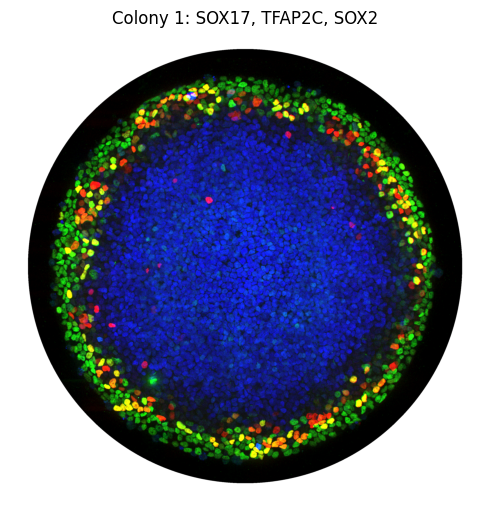

In [4]:
# Render a pseudocolored RGB overlay of raw microscopy images 

colID = 1 
stains = ['SOX17', 'TFAP2C', 'SOX2']

fig, ax = plt.subplots(1, 1, figsize=(5, 5), constrained_layout=True)

RGBbase, image_meta = IIF.makeRGBbase(col, colID, stains, dataDir, outer_margin=100, crop_margin=140,
                            center_x_margin=0, center_y_margin=0, rdStr='RD')

ax.imshow(RGBbase)
ax.axis('off')
ax.set_title(f'Colony {colID}: {", ".join(stains)}')


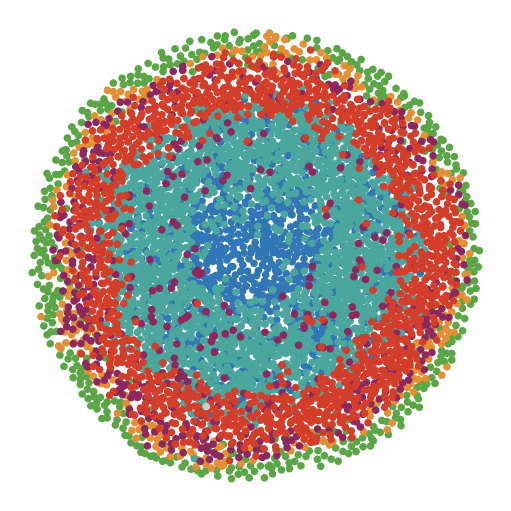

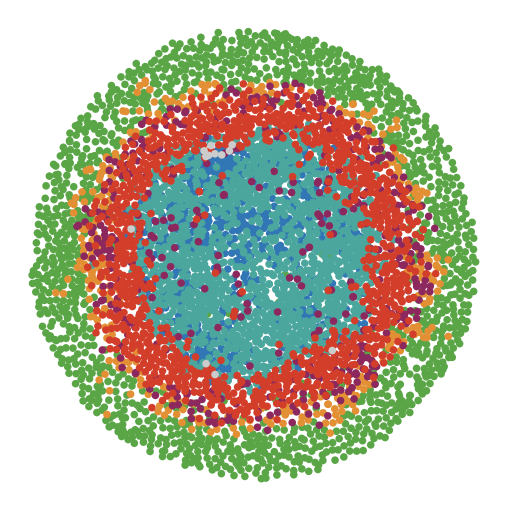

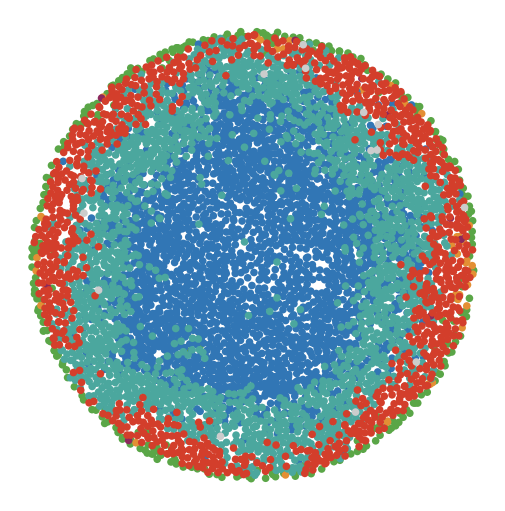

In [12]:
for (cond, colID) in zip(conditions, [1,7,14]):
    fig, ax = plt.subplots(1,1, figsize=(5,5), constrained_layout=True)
    ms = 30
    lim = 350
    col[colID].scatter_fates(ms=ms, thresh=thresh, ax=ax, legend=False)
    #ax.set_xlim([-lim,lim]);
    #ax.set_ylim([lim,-lim]);

    plt.savefig(dataDir+"/Fig4/" + 'fates_scatter_' + cond + '_col' + str(colID) + file_suffix)

## Predictions across conditions

In [38]:
# make cross condition predictions 

importlib.reload(IIF)

signals = ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'cytopERK']  # 5D, matches fig3n_5D
hyperparam = {'HIDDEN_DIM': 32, 'N_LAYERS': 2, 'LATENT_DIM': 2}
N_run = 3
D = len(signals)
out_dir = dataDir + '/Fig4_VIB'

data_b50 = data[data['condition'] == 'B50']

# B50: leave-one-colony-out self-prediction
IIF.run_vib_self(data_b50, signals, gene_names, hyperparam, N_run=N_run,
                  out_dir=out_dir, out_prefix=f'{D}D_selfB50', recompute=False)
pred_sub_b50 = IIF.load_vib_self(data_b50, signals, gene_names, hyperparam, N_run=N_run,
                                  out_dir=out_dir, out_prefix=f'{D}D_selfB50')['avg']

# B10/B200: fresh model trained on all of B50, predicting the other doses
pred_by_cond = {'B50': pred_sub_b50}
for cond in ['B10', 'B200']:
    data_cond = data[data['condition'] == cond]
    preds_cond = IIF.run_vib_cross_condition(
        data_b50, data_cond, signals, gene_names, hyperparam, N_run=N_run,
        out_dir=out_dir, out_prefix=f'cross_B50to{cond}_{D}D', recompute=False)
    pred_by_cond[cond] = preds_cond['avg']

pred_sub = pd.concat(pred_by_cond.values())
pred_sub = pred_sub.reindex(data.index)

col_pred = dict()
pred = dict()

col_pred = dict()

for colID in np.unique(pred_sub['Colony']):
    col_pred[colID] = IIF.Colony(pred_sub[pred_sub['Colony']==colID], colID, meta, features=feature_names, nominalRadius=350)
    col_pred[colID].calcRadialProfiles(cellsPerBin=100, overlap=0, dr=8)
    col_pred[colID].calcPosError(sigma=1)

pred = IIF.MPexperiment(col_pred, meta)
pred.calcRadialProfiles(cellsPerBin=100, overlap=0)

Run 0/3 -- already exists, skipping load: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/Fig4_VIB/5D_selfB50_run0.csv
Run 1/3 -- already exists, skipping load: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/Fig4_VIB/5D_selfB50_run1.csv
Run 2/3 -- already exists, skipping load: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/Fig4_VIB/5D_selfB50_run2.csv
Run 0/3 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/Fig4_VIB/5D_selfB50_run0.csv
Run 1/3 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/Fig4_VIB/5D_selfB50_run1.csv
Run 2/3 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/Fig4_VIB/5D_selfB50_run2.csv
Run 0/3 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/Fig4_VIB/cross_B50toB10_5D_run0.csv
Run 1/3 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/Fig4_VIB/cross_B50toB10_5D_r

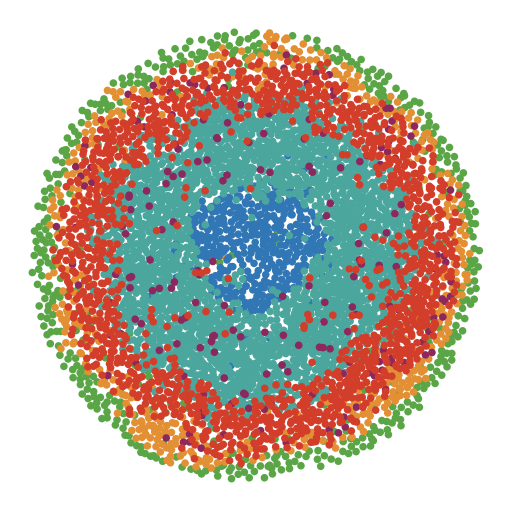

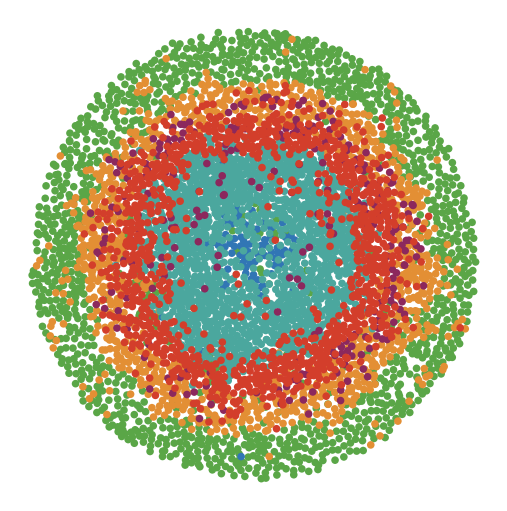

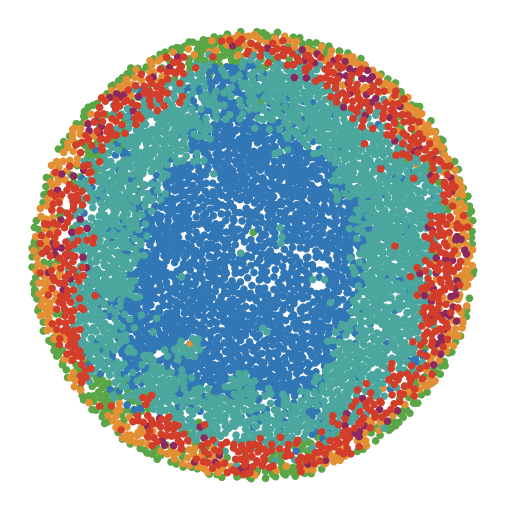

In [17]:
for (cond, colID) in zip(conditions, [1,7,14]):
    fig, ax = plt.subplots(1,1, figsize=(5,5), constrained_layout=True)
    ms = 30
    lim = 350
    col_pred[colID].scatter_fates(ms=ms, thresh=thresh, ax=ax, legend=False)
    #ax.set_xlim([-lim,lim]);
    #ax.set_ylim([lim,-lim]);

    plt.savefig(dataDir+"/Fig4/" + 'fates_scatter_' + cond + '_col' + str(colID) + '_pred_'+ str(len(signals)) + 'D' + file_suffix)

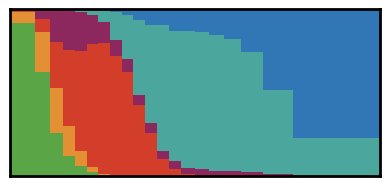

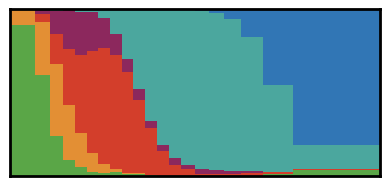

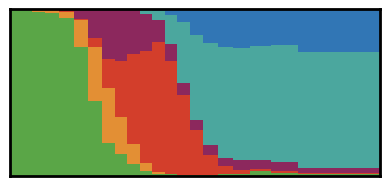

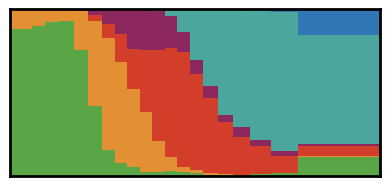

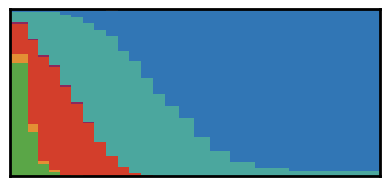

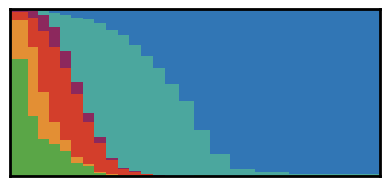

In [39]:
# MAKE HISTOGRAMS OF SPATIAL DISTRIBUTION

n_bins = 20
thresh_boundary = 0.5 # boundaries are half maximum of fate
fate_names_ordered = list(IIF.colmap_fates.keys())
N_fates = len(fate_names_ordered)
colors = list(IIF.colmap_fates.values())

# initialize boundaries array: (n_cond, inner/outer, n_fates, exp/pred)
boundaries_all = np.full((len(conditions), 2, N_fates, 2), np.nan)

sig_str = '_'.join(sorted(signals))
pred_subs = {sig_str: {'avg': pred_sub}}

for pi, (pred_sub_name, pred_sub) in enumerate(pred_subs.items()):

    pred_sub = pred_sub['avg']
    
    for i, cond in enumerate(conditions):
    
        for mode_sim in [0, 1]:
    
            if mode_sim == 0:
                data_cond = data[data['condition'] == cond]
            elif mode_sim == 1:
                data_cond = pred_sub[pred_sub['condition'] == cond]
            
            fates, fate_names = IIF.return_fates(data_cond, thresh=thresh)
            
            # bin by radial distance
            binning = pd.qcut(data_cond['CircleEdgeDist'], q=n_bins, labels=False, duplicates='drop').to_frame(name='r_bin')
            binning['fate'] = fates

            # get bin centers in microns
            bin_edges = pd.qcut(data_cond['CircleEdgeDist'], q=n_bins, duplicates='drop', retbins=True)[1]
            bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2

            # fate counts per bin
            fate_counts = binning.groupby(['r_bin', 'fate']).size().unstack(fill_value=0)
            fate_counts = fate_counts.reindex(columns=fate_names_ordered, fill_value=0)

            # normalize per fate (each fate peaks at 1) for boundary detection
            fate_counts_byfate = fate_counts.div(fate_counts.sum(axis=0), axis=1)
            fate_counts_byfate_norm = fate_counts_byfate.div(fate_counts_byfate.max(axis=0).replace(0, 1), axis=1)

            # normalize per bin for bar plot
            fate_counts_norm = fate_counts.div(fate_counts.sum(axis=1), axis=0)

            # fill boundaries array
            for fi, fate in enumerate(fate_names_ordered):

                if fate not in fate_counts_byfate_norm.columns:
                    continue

                profile = fate_counts_byfate_norm[fate].values
                n = len(profile)

                if profile[0] > thresh_boundary:
                    boundaries_all[i, 0, fi, mode_sim] = 0
                if profile[-1] > thresh_boundary:
                    boundaries_all[i, 1, fi, mode_sim] = bin_centers[-1]

                for b in range(1, n - 1):
                    if profile[b-1] < thresh_boundary and profile[b+1] > thresh_boundary:
                        boundaries_all[i, 0, fi, mode_sim] = bin_centers[b]
                    elif profile[b-1] > thresh_boundary and profile[b+1] < thresh_boundary:
                        boundaries_all[i, 1, fi, mode_sim] = bin_centers[b]
            
            # distribution bar plot
            fig, ax = plt.subplots(1, 1, figsize=(4, 3))

            # old version with equal width bin display
            # fate_counts_norm.plot(kind='bar', color=colors, stacked=True, ax=ax, width=1, legend=False)
            # ax.set_xticks([0, n_bins-1], labels=['edge', 'center'], rotation=0)
            # ax.set_xlim(-0.5, n_bins - 0.5)

            bin_widths = bin_edges[1:] - bin_edges[:-1]
            bottom = np.zeros(len(bin_centers))
            for fi, fate in enumerate(fate_names_ordered):
                if fate not in fate_counts_norm.columns:
                    continue
                vals = fate_counts_norm[fate].values
                ax.bar(bin_centers, vals, width=bin_widths, bottom=bottom,
                    color=colors[fi], align='center')
                bottom += vals
            #ax.set_xticks([bin_centers[0], bin_centers[-1]], labels=['edge', 'center'])
            ax.set_xticks([])
            ax.set_xlim(bin_edges[0], bin_edges[-1])
            #ax.set_title(cond)
            ax.set_xlabel(None)
            ax.set_yticks([])
            ax.set_ylim(0, 1)
            
            sw = 2
            ax.set_box_aspect(0.45)
            for spine in ax.spines.values():
                spine.set_linewidth(sw)
            
            mode_str = 'exp' if mode_sim == 0 else 'pred'
            plt.tight_layout()
            plt.savefig(dataDir+"/Fig4/" + f'fatedist_{str(pred_sub_name)}_{cond}_{mode_str}_{str(len(signals))}D.png', bbox_inches='tight')
            plt.show()
            plt.close()

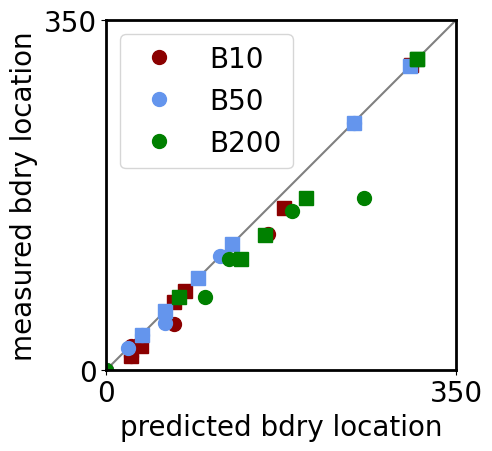

In [21]:
# fate boundaries

fs = 20
sw = 2

fig, ax = plt.subplots(1, 1, figsize=(5, 5))

conditions_ordered = ['B10', 'B50', 'B200']

ax.plot([0, 350], [0, 350], '-', color='grey')

for it_cond, cond in enumerate(conditions_ordered):

    color = fns_plot.return_colmaps('conditions')[conditions.index(cond)]
    boundaries = boundaries_all[conditions.index(cond), :, :, :]

    ax.plot(boundaries[0, :, 1], boundaries[0, :, 0], 'o', color=color, label=cond, markersize=10)
    ax.plot(boundaries[1, :, 1], boundaries[1, :, 0], 's', color=color, markersize=10)

ax.set_xlim([0, 350])
ax.set_ylim([0, 350])
ax.set_xticks([0, 350])
ax.set_yticks([0, 350])
ax.tick_params(labelsize=fs)
ax.set_xlabel('predicted bdry location', fontsize=fs)
ax.set_ylabel('measured bdry location', fontsize=fs)
ax.set_box_aspect(1)
ax.legend(fontsize=fs)

for spine in ax.spines.values():
    spine.set_linewidth(sw)

plt.tight_layout()
plt.savefig(dataDir+"/Fig4/" + f'fates_boundaries_allcond_{str(len(signals))}D.png')
plt.show()

### Compare prediction across vs within conditions

In [69]:
importlib.reload(IIF);
N_run = 5
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}

data_B10 = data[data['condition']=='B10']
data_B200 = data[data['condition']=='B200']

IIF.run_vib_self(data_B10, signals, gene_names, hyperparam, N_run=N_run,
                  out_dir=out_dir, out_prefix=f'{D}D_selfB10', recompute=True)
within_pred_B10 = IIF.load_vib_self(data_B10, signals, gene_names, hyperparam, N_run=N_run,
                                     out_dir=out_dir, out_prefix=f'{D}D_selfB10')['avg']

IIF.run_vib_self(data_B200, signals, gene_names, hyperparam, N_run=N_run,
                  out_dir=out_dir, out_prefix=f'{D}D_selfB200', recompute=True)
within_pred_B200 = IIF.load_vib_self(data_B200, signals, gene_names, hyperparam, N_run=N_run,
                                      out_dir=out_dir, out_prefix=f'{D}D_selfB200')['avg']


Run 0/5
  col: 14
  col: 15
  col: 16
  col: 17
  col: 18
Elapsed time: 15.2 seconds
Run 1/5
  col: 14
  col: 15
  col: 16
  col: 17
  col: 18
Elapsed time: 14.4 seconds
Run 2/5
  col: 14
  col: 15
  col: 16
  col: 17
  col: 18
Elapsed time: 14.2 seconds
Run 3/5
  col: 14
  col: 15
  col: 16
  col: 17
  col: 18
Elapsed time: 14.3 seconds
Run 4/5
  col: 14
  col: 15
  col: 16
  col: 17
  col: 18
Elapsed time: 15.1 seconds
Run 0/5 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/Fig4_VIB/5D_selfB10_run0.csv
Run 1/5 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/Fig4_VIB/5D_selfB10_run1.csv
Run 2/5 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/Fig4_VIB/5D_selfB10_run2.csv
Run 3/5 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/Fig4_VIB/5D_selfB10_run3.csv
Run 4/5 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMP

In [70]:
within_pred_combined = pred_subs['LEF1_cytopERK_ncSMAD23_ncYAP_pSMAD1']['avg'].copy()

# overwrite gene predictions for B10 and B200 with within-condition predictions
b10_idx = within_pred_combined['condition'] == 'B10'
b200_idx = within_pred_combined['condition'] == 'B200'

within_pred_combined.loc[b10_idx, gene_names] = within_pred_B10[gene_names].values
within_pred_combined.loc[b200_idx, gene_names] = within_pred_B200[gene_names].values

In [71]:
importlib.reload(IIF);

col_withinpred = dict()

for colID in np.unique(within_pred_combined['Colony']):
    col_withinpred[colID] = IIF.Colony(within_pred_combined[within_pred_combined['Colony']==colID], colID, meta, features=feature_names, nominalRadius=350)
    col_withinpred[colID].calcRadialProfiles(cellsPerBin=100, overlap=0, dr=8)
    col_withinpred[colID].calcPosError(sigma=1)

withinpred = IIF.MPexperiment(col_withinpred, meta)
withinpred.calcRadialProfiles(cellsPerBin=100, overlap=0)

B50, Nbins = 304
B200, Nbins = 288
B10, Nbins = 252


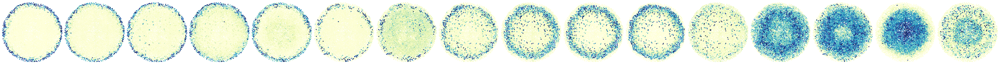

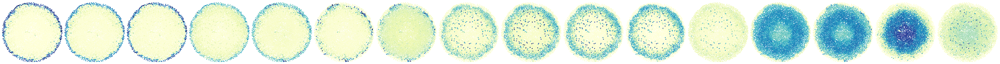

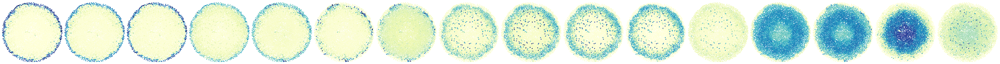

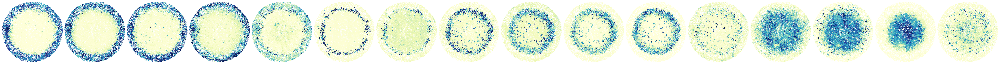

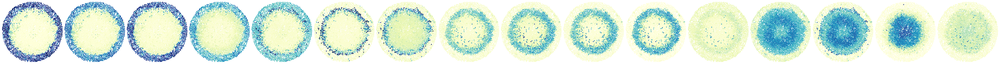

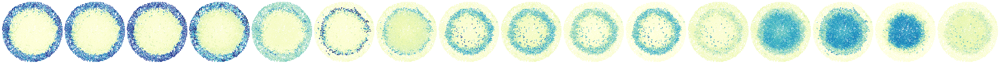

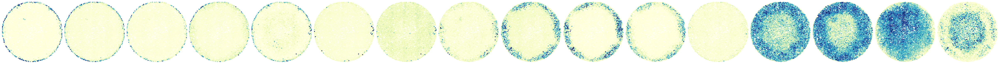

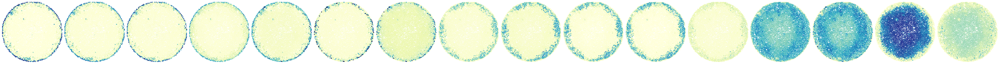

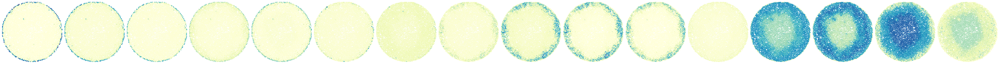

In [72]:
m=1
n = len(gene_names)
vlim = dict()
ms = 10

for (cond, colID) in zip(conditions, [1,7,14]):

    fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)
    
    for i,f in enumerate(gene_names):
    
        if cond=='B50':
            vlim[f] = col[colID].scatter(f, ms=ms, ax=ax[i], tol=(1,99))
        else:
            col[colID].scatter(f, ms=ms, ax=ax[i], vmin=vlim[f][0], vmax=vlim[f][1])
        
        ax[i].set_xlim([-lim,lim])
        ax[i].set_ylim([lim,-lim])
    
    plt.savefig(dataDir+"/FigS9/" + 'markers_scatter_' + cond + f'_col{str(colID)}_{str(len(signals))}D.png')
    plt.show()
    plt.close()
    
    fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)
    
    for i,f in enumerate(gene_names):

        col_pred[colID].scatter(f, ms=ms, ax=ax[i], vmin=vlim[f][0], vmax=vlim[f][1])
        
        ax[i].set_xlim([-lim,lim])
        ax[i].set_ylim([lim,-lim])
    
    plt.savefig(dataDir+"/FigS9/" + 'markers_scatter_' + cond + f'_col{str(colID)}_pred_across_{str(len(signals))}D.png')
    plt.show()
    plt.close()

    fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)
    
    for i,f in enumerate(gene_names):

        col_withinpred[colID].scatter(f, ms=ms, ax=ax[i], vmin=vlim[f][0], vmax=vlim[f][1])
        
        ax[i].set_xlim([-lim,lim])
        ax[i].set_ylim([lim,-lim])
    
    plt.savefig(dataDir+"/FigS9/" + 'markers_scatter_' + cond + f'_col{str(colID)}_pred_within_{str(len(signals))}D.png')
    plt.show()
    plt.close()

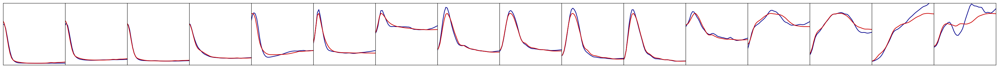

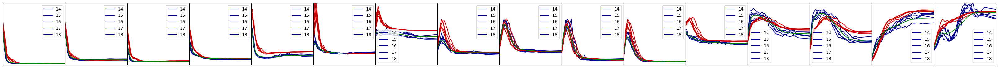

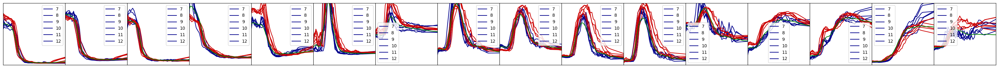

In [ ]:
# OVERLAY RADIAL PROFILES 
# ---- plot B50 first and save ylims ----
fig, ax = plt.subplots(1, n, figsize=(n*2, 2))
ylims_B50 = {}

for i, f in enumerate(gene_names):
    exp.plotRadialProfiles(f, 'B50', mode='cells', sigma=1, color='darkblue', ax=ax[i], errorbars=False)
    pred.plotRadialProfiles(f, 'B50', mode='cells', sigma=1, color=[0.8, 0, 0], ax=ax[i], errorbars=False)
    ax[i].set_xticks([])
    ax[i].set_yticks([])
    ax[i].set_ylabel(None)
    ax[i].set_xlabel(None)
    ylims_B50[f] = ax[i].get_ylim()  # save ylim for each gene

plt.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0, hspace=0)
plt.show()

# ---- plot B10/B200 with same ylims ----
for cond in ['B10','B200']:

    fig, ax = plt.subplots(1, n, figsize=(n*2, 2))

    for i, f in enumerate(gene_names):
        exp.plotRadialProfiles(f, cond, mode='cells', sigma=1, color='darkblue', ax=ax[i], errorbars=False)
        pred.plotRadialProfiles(f, cond, mode='cells', sigma=1, color=[0.8, 0, 0], ax=ax[i], errorbars=False)
        #exp.plotRadialProfiles(f, cond, mode='colonies_individual', color='darkblue', ax=ax[i])
        #pred.plotRadialProfiles(f, cond, mode='colonies_individual', color=[0.8, 0, 0], ax=ax[i])
        withinpred.plotRadialProfiles(f, cond, mode='cells', sigma=1, color='green', ax=ax[i], errorbars=False)
        ax[i].set_xticks([])
        ax[i].set_yticks([])
        ax[i].set_ylabel(None)
        ax[i].set_xlabel(None)
        ax[i].set_ylim(ylims_B50[f])  # apply B50 ylim

    plt.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0, hspace=0)
    plt.savefig(dataDir+"/FigS9/" + 'profile_predwithin_v_across' + cond + f'_{str(len(signals))}D.png')
    plt.show()

### Performance

In [74]:
across_pred_combined = pred_subs['LEF1_cytopERK_ncSMAD23_ncYAP_pSMAD1']['avg'].copy()
pred_subs_2 = {'within': {'avg': within_pred_combined}, 'across': {'avg': across_pred_combined}}

In [75]:
# CALCULATE PERFORMANCE
performances, _ = IIF.calcPerformance(data, pred_subs_2, thresh, gene_names)

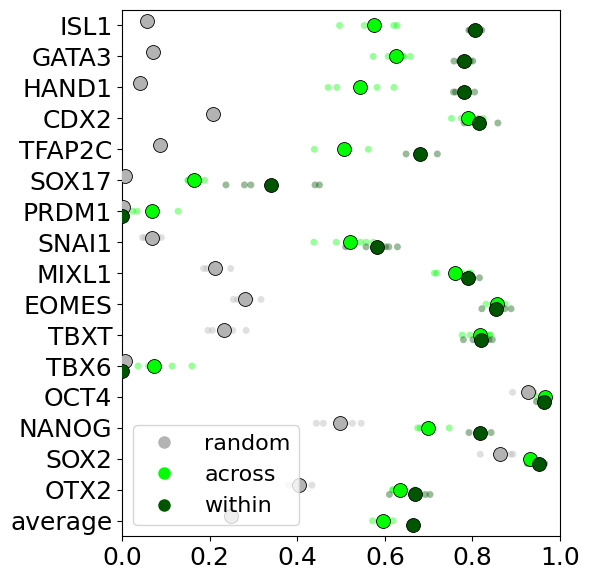

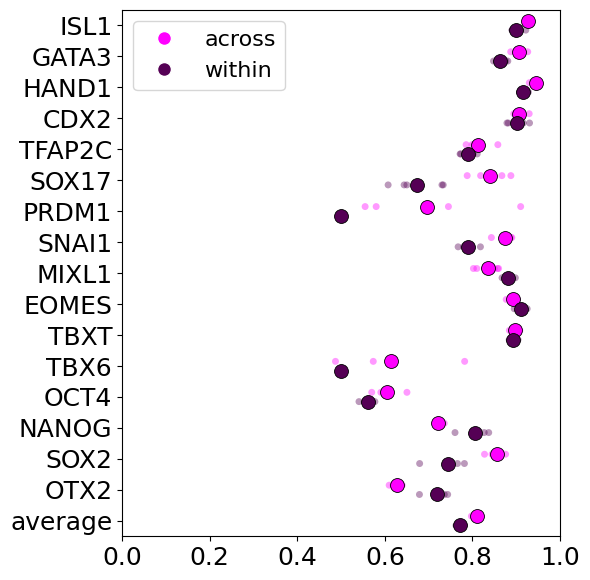

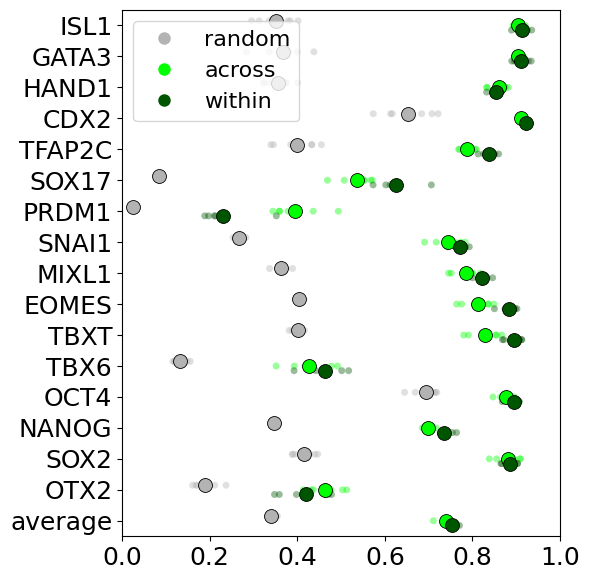

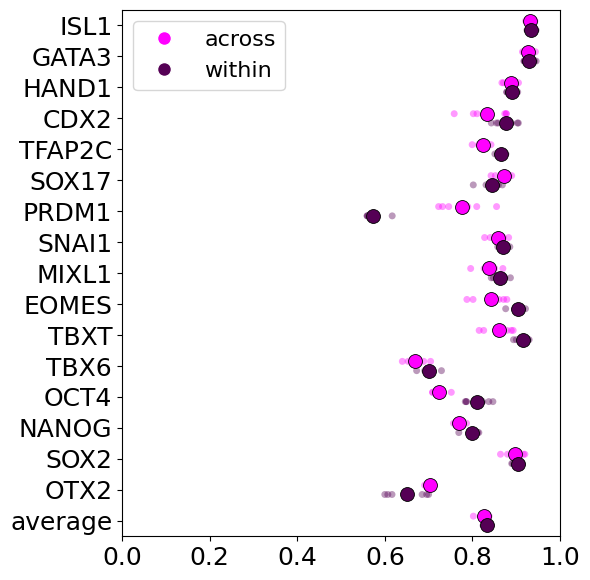

In [76]:
# ============================================================
# PLOT: within vs across vs random - one plot per condition, balanced accuracy in place
# of accuracy. Reuses pred_by_cond ('across', from run_vib_cross_condition) and
# within_pred_B10/within_pred_B200 ('within', from run_vib_self).
# ============================================================
labels = gene_names + ['marker_avg']
labels_tick = labels.copy()
labels_tick[-1] = 'average'

within_by_cond = {'B10': within_pred_B10, 'B200': within_pred_B200}

for cond in ['B10', 'B200']:

    data_cond = data[data['condition'] == cond]
    colonies_cond = data_cond['Colony'].values

    across_sub = pred_by_cond[cond].loc[data_cond.index]
    within_sub = within_by_cond[cond].loc[data_cond.index]

    perfold_across = IIF.compute_marker_performance_perfold(data_cond, across_sub, colonies_cond, gene_names, thresh)
    perfold_within = IIF.compute_marker_performance_perfold(data_cond, within_sub, colonies_cond, gene_names, thresh)

    perfold_cond = {}
    for key, pf in [('across', perfold_across), ('within', perfold_within)]:
        avg_rows = pf.groupby('fold')[['balanced_accuracy', 'f1', 'f1_rand']].mean().reset_index()
        avg_rows['gene'] = 'marker_avg'
        perfold_cond[key] = pd.concat([pf, avg_rows], ignore_index=True)

    for score, base_color in [('f1', np.array([0, 1, 0])), ('balanced_accuracy', np.array([1, 0, 1]))]:

        series = [(perfold_cond['across'], score, tuple(base_color / 1)),
                  (perfold_cond['within'], score, tuple(base_color / 3))]
        legend_labels = ['across', 'within']

        # random baseline only shown for f1, matching the original -- balanced accuracy's
        # chance level is a constant 0.5 by construction, not a data-dependent quantity
        # the way f1_rand (marker positivity rate) is
        if score == 'f1':
            series = [(perfold_cond['across'], 'f1_rand', (0.7, 0.7, 0.7))] + series
            legend_labels = ['random'] + legend_labels

        IIF.plot_perfold_comparison(
            series, 'gene', labels,
            dataDir + f'/FigS9/marker_{score}_within_vs_across_{cond}_{str(len(signals))}D.png',
            legend_labels=legend_labels, tick_labels=labels_tick,
            figsize=(6, 0.3 * len(labels) + 0.8))


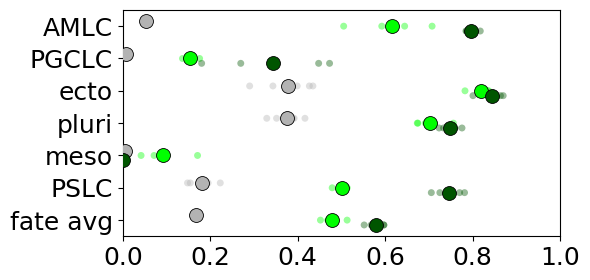

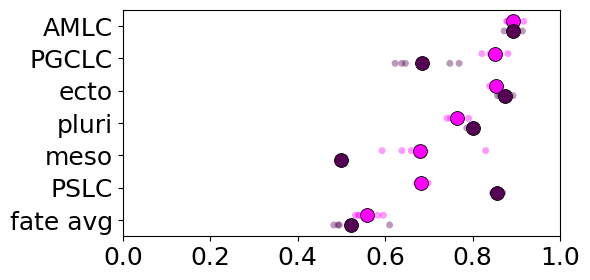

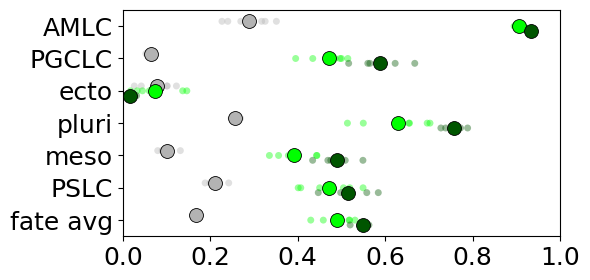

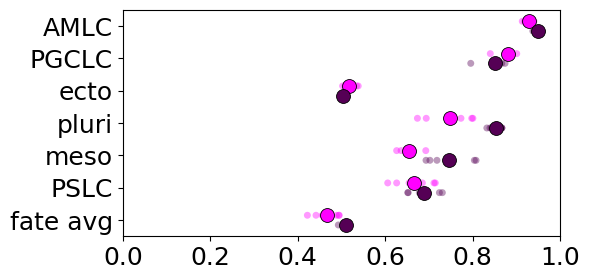

In [77]:
# ============================================================
# PLOT: within vs across vs random - FATE - one plot per condition, balanced accuracy in
# place of accuracy. Reuses pred_by_cond ('across') and within_pred_B10/within_pred_B200
# ('within') from earlier.
# ============================================================
category_list = ['AMLC', 'PGCLC', 'ecto', 'pluri', 'meso', 'PSLC']
labels = category_list + ['all']
labels_tick = category_list + ['fate avg']

within_by_cond = {'B10': within_pred_B10, 'B200': within_pred_B200}

for cond in ['B10', 'B200']:

    data_cond = data[data['condition'] == cond]
    colonies_cond = data_cond['Colony'].values

    true_labels_cond, _ = IIF.return_fates(data_cond, thresh=thresh)

    across_sub = pred_by_cond[cond].loc[data_cond.index]
    within_sub = within_by_cond[cond].loc[data_cond.index]
    pred_labels_across, _ = IIF.return_fates(across_sub, thresh=thresh)
    pred_labels_within, _ = IIF.return_fates(within_sub, thresh=thresh)

    perfold_cond = {}
    for key, pred_labels in [('across', pred_labels_across), ('within', pred_labels_within)]:
        records = IIF.compute_category_performance_perfold(true_labels_cond, pred_labels, colonies_cond,
                                                             category_list, aggregate_name='all')
        perfold_cond[key] = pd.DataFrame(records)

    for score, base_color in [('f1', np.array([0, 1, 0])), ('balanced_accuracy', np.array([1, 0, 1]))]:

        series = [(perfold_cond['across'], score, tuple(base_color / 1)),
                  (perfold_cond['within'], score, tuple(base_color / 3))]

        if score == 'f1':
            series = [(perfold_cond['across'], 'f1_rand', (0.7, 0.7, 0.7))] + series

        IIF.plot_perfold_comparison(
            series, 'category', labels,
            dataDir + f'/FigS9/fate_{score}_within_vs_across_{cond}_{str(len(signals))}D.png',
            tick_labels=labels_tick,
            figsize=(6, 0.3 * len(labels) + 0.8))


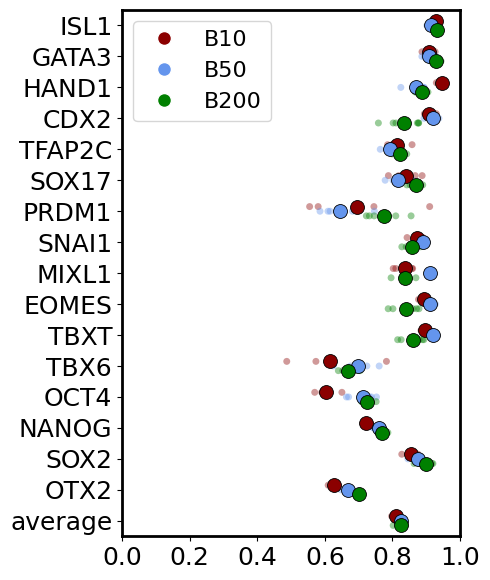

In [78]:
# ============================================================
# PLOT: balanced accuracy per marker, comparing B10/B50/B200, same color code as
# fates_boundaries_allcond
# ============================================================
labels = gene_names + ['marker_avg']
labels_tick = labels.copy()
labels_tick[-1] = 'average'

condition_colors = dict(zip(conditions, fns_plot.return_colmaps('conditions')))

perfold_by_cond = {}
for cond in conditions_ordered:  # ['B10', 'B50', 'B200']
    data_cond = data[data['condition'] == cond]
    colonies_cond = data_cond['Colony'].values
    pred_cond = pred_sub.loc[data_cond.index]

    pf = IIF.compute_marker_performance_perfold(data_cond, pred_cond, colonies_cond, gene_names, thresh)
    avg_rows = pf.groupby('fold')[['balanced_accuracy', 'f1', 'f1_rand']].mean().reset_index()
    avg_rows['gene'] = 'marker_avg'
    perfold_by_cond[cond] = pd.concat([pf, avg_rows], ignore_index=True)

series = [(perfold_by_cond[cond], 'balanced_accuracy', condition_colors[cond]) for cond in conditions_ordered]

IIF.plot_perfold_comparison(
    series, 'gene', labels,
    dataDir + f'/Fig4/marker_balanced_acc_across_conditions_comparison_{str(len(signals))}D.png',
    legend_labels=conditions_ordered, tick_labels=labels_tick,
    figsize=(5, 0.3 * len(labels) + 0.8), sw=2)


### Latent space

In [79]:
# Load models from Fig 3
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
genes = gene_names

cond = 'B50'
data_cond = data[data['condition']==cond]

feat_train = data_cond[signals] 
tar_train = data_cond[gene_names]

run = 3
vib = IIF.VIB(feat_train, tar_train, hyperparam)
vib.model = torch.load(
    os.path.join(dataDir, f'modelws_{run}_{len(signals)}D.pth'),
    map_location='cpu', weights_only=False
)
vib.model = vib.model.to(device)
model = vib.model

# load the orientation transform (Procrustes + cosmetic rotation to the reference
# checkpoint) established in fig3, so this latent space matches fig3's exactly
orientation = np.load(dataDir + f'/latent_orientation_seed{run}_{len(signals)}D.npz')
M, b = orientation['M'], orientation['b']


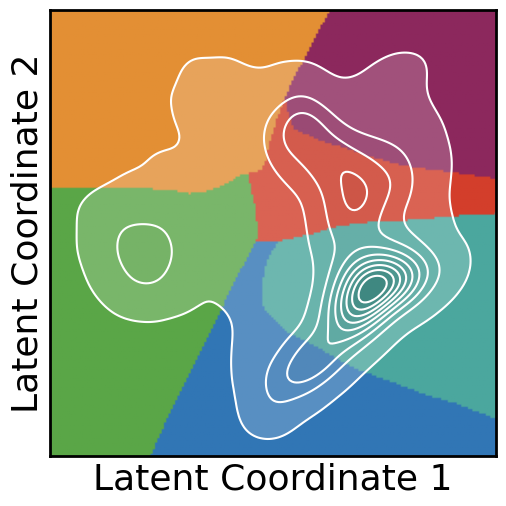

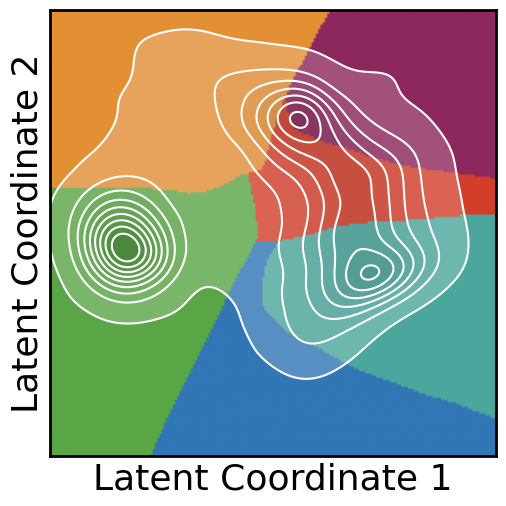

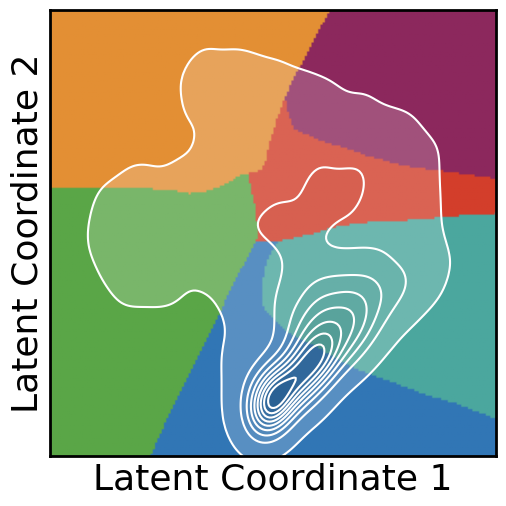

In [80]:
fs = 26
# load fate map
L1grid_scaled = np.load(dataDir + '/fatemap_L1grid_scaled.npy')
L2grid_scaled = np.load(dataDir + '/fatemap_L2grid_scaled.npy')
fates = list(np.load(dataDir + '/fatemap_fates.npy'))
L1smin, L1smax, L2smin, L2smax = np.load(dataDir + '/fatemap_limits.npy')
L1mean, L1std = np.load(dataDir + '/fatemap_L1mean_L1std.npy')
L2mean = np.load(dataDir + '/fatemap_L2mean.npy')

# precompute rgb image once
rgb_image = np.zeros((200, 200, 3))
for i, fate in enumerate(fates):
    color = IIF.colmap_fates[fate]
    rgb_image[i // 200, i % 200] = mcolors.to_rgb(color)

# now loop over conditions
for cond in conditions:

    mask = (data['condition'] == cond)

    # encode with the B50-trained model
    X = vib.scaler_X_run.transform(data.loc[mask, signals])
    X = torch.FloatTensor(X).to(device)

    model.eval()
    with torch.no_grad():
        mu, _ = model.encode(X)
        
    L_scaled = mu.cpu().numpy() @ M + b
    L1_scaled = L_scaled[:, 0]
    L2_scaled = L_scaled[:, 1]

    # plot
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    ax.imshow(rgb_image, origin='lower', extent=[L1smin, L1smax, L2smin, L2smax])

    # KDE
    values = np.vstack([L1_scaled, L2_scaled])
    kernel = sp.stats.gaussian_kde(values)
    kde_at_data = kernel(values)
    vmin = np.percentile(kde_at_data, 1)
    kde_grid = kernel(np.vstack([L1grid_scaled.ravel(), L2grid_scaled.ravel()]))
    kde_grid = kde_grid.reshape(L1grid_scaled.shape)
    vmax = kde_grid.max()
    levels = np.linspace(vmin, vmax, 10)

    ax.contourf(L1grid_scaled, L2grid_scaled, kde_grid,
                levels=levels, cmap='Greys', alpha=0.2)
    ax.contour(L1grid_scaled, L2grid_scaled, kde_grid,
               levels=levels, colors='white', linewidths=1.5)

    ax.set_xlim(L1smin, L1smax)
    ax.set_ylim(L2smin, L2smax)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('Latent Coordinate 1', fontsize=fs)
    ax.set_ylabel('Latent Coordinate 2', fontsize=fs)
    ax.set_aspect('equal', adjustable='box')

    for spine in ax.spines.values():
        spine.set_linewidth(sw)

    plt.tight_layout(pad=0.5)
    plt.savefig(dataDir+'/Fig4/LS_fate_' + str(len(signals)) + 'D_run' + str(run) + '_' + cond + '_kde.png', dpi=150, bbox_inches='tight')
    plt.show()